# Powder reduction for full_instrument

Reduce one ASCII run to $Q$ and energy transfer. The equations and
procedure are explained below. Run the notebook cells in order.

## Imports and constants

These notebooks read the McCode ASCII output of full_instrument.ipynb.
The procedure follows the HYSPEC reference, with the current source and
geometry. Each notebook contains all its own functions; neither depends
on the Python scripts. Run the cells in order. Requirements are NumPy
and Matplotlib.

Wavelengths are in Å, distances in metres and times in seconds.

$$v=\frac{C}{\lambda},\quad C=3956.0346\ 
\mathrm{m\,s^{-1}\,\mathring{A}},\qquad
E=\frac{81.8042}{\lambda^2}\ \mathrm{meV}.$$

In [90]:
import io
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("/run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/full_instrument")
VELOCITY = 3956.0346  # v [m/s] = VELOCITY / wavelength [Angstrom]
ENERGY = 81.8042     # E [meV] = ENERGY / wavelength [Angstrom]**2
OUTPUT_CSV = ROOT / "powder_reduced.csv"

## Read the ASCII parameters and tube histograms

For $n_t$ equally spaced time bins,

$$\Delta t=\frac{t_{\max}-t_{\min}}{n_t},\qquad
t_j=t_{\min}+\left(j+\frac12\right)\Delta t.$$

The reader checks the axis labels and data dimensions.

In [91]:
def read_parameters(run):
    """Read the actual values used in this run, rather than notebook defaults."""
    run = Path(run)
    parameters = {}
    for line in (run / "mccode.sim").read_text().splitlines():
        match = re.match(r"\s*Param:\s*([\w]+)\s*=\s*(.*)", line)
        if match:
            try:
                parameters[match[1]] = float(match[2])
            except ValueError:
                pass  # String parameters are not needed for these calculations.
    return parameters

def read_tube(path):
    """Return TOF centers, dt, height-summed signal, error and event count."""
    text = Path(path).read_text()
    shape = re.search(r"^# type: array_2d\((\d+),\s*(\d+)\)", text, re.M)
    limits = re.search(r"^# xylimits:\s*(.*)", text, re.M)
    if shape is None or limits is None:
        raise ValueError(f"{path}: expected a McCode array_2d header")
    if not re.search(r"^# xlabel:\s*y \[m\]", text, re.M):
        raise ValueError(f"{path}: first axis must be tube y in metres")
    if not re.search(r"^# ylabel:\s*TOF \[s\]", text, re.M):
        raise ValueError(f"{path}: second axis must be TOF in seconds")

    ny, nt = map(int, shape.groups())
    ymin, ymax, tmin, tmax = map(float, limits[1].split())
    values = np.loadtxt(io.StringIO(text), ndmin=2)
    if values.shape != (3*nt, ny):
        raise ValueError(f"{path}: expected three ({nt}, {ny}) data blocks")
    if not np.isfinite(values).all() or np.any(values[nt:] < 0):
        raise ValueError(f"{path}: nonfinite data or negative errors/counts")
    if tmax <= tmin or ymax <= ymin:
        raise ValueError(f"{path}: invalid axis limits")

    intensity, error, events = values.reshape(3, nt, ny)
    dt = (tmax - tmin)/nt
    tof = tmin + (np.arange(nt) + 0.5)*dt
    return (tof, dt, intensity.sum(axis=1),
            np.sqrt((error**2).sum(axis=1)), events.sum(axis=1))

## Flight paths and source emission time

The uninterrupted FANTASTIC elliptic guide gives the nominal primary path

$$L_i=d_{\mathrm{source,guide}}+L_{\mathrm{guide}}+
d_{\mathrm{guide,sample}}=0.5+35+1.5=37\ \mathrm{m}.$$

The code reads this run's saved parameters. For older runs with choppers,
it instead uses their saved geometry:

$$L_i=d_{\mathrm{PSC}}+L_{\mathrm{guide2}}+0.06+l_3+
d_{\mathrm{guide,sample}}.$$

First-order Bragg diffraction gives

$$A5=\arcsin\left(\frac{\lambda_f}{2d_{\mathrm{analyser}}}\right).$$

The fixed detector-arm separation $L_2$ differs from the reflected ray
length. The nominal secondary path is

$$L_f=d_{\mathrm{sample,analyser}}+\frac{L_2}{\sin(2A5)}.$$

The source emission-time estimate is

$$t_0=\frac{t_{\mathrm{pulse}}}{2}
+\tau_{\mathrm{moderator}}\frac{n_{\mathrm{moderator}}+1}
{n_{\mathrm{moderator}}}.$$

The source time window is not a mean emission time. This estimate does
not resolve the full pulse shape or chopper conditional timing.

In [92]:
def geometry(parameters):
    """Calculate the current instrument's nominal paths and emission center."""
    p = parameters
    if "guide_length" in p:
        primary_keys = ("d_source_guide", "guide_length", "d_guide_sample")
    else:
        # Older runs used three straight guides separated by choppers.
        primary_keys = ("chopper_distance", "guide2_length", "l3", "d_guide_sample")
    required = primary_keys + (
                "d_sample_analyser", "analyser_detector_distance", "analyser_d",
                "lambda_f", "pulse_length", "moderator_tau", "moderator_n",
                "lambda_min", "lambda_max", "detector_x")
    missing = [key for key in required if key not in p]
    if missing:
        raise ValueError(f"Missing run parameters: {', '.join(missing)}")
    if not all(np.isfinite(p[key]) for key in required):
        raise ValueError("Geometry/source parameters must be finite")
    if not (0 < p["lambda_f"] < 2*p["analyser_d"]):
        raise ValueError("lambda_f must satisfy 0 < lambda_f < 2*analyser_d")
    if p["moderator_n"] <= 0:
        raise ValueError("moderator_n must be positive")

    li_path = sum(p[key] for key in primary_keys)
    if "guide_length" not in p:
        li_path += 0.06  # Three 20 mm gaps in the older chopped beamline.
    a5 = np.arcsin(p["lambda_f"]/(2*p["analyser_d"]))
    lf_path = p["d_sample_analyser"] + p["analyser_detector_distance"]/np.sin(2*a5)
    t0 = p["pulse_length"]/2 + p["moderator_tau"]*(p["moderator_n"]+1)/p["moderator_n"]
    if li_path <= 0 or lf_path <= 0 or not np.isfinite(t0):
        raise ValueError("Flight paths must be positive and t0 finite")
    delta = np.arctan((p["detector_x"]/4 + 0.0001)/lf_path)
    return li_path, lf_path, t0, delta

## Incident wavelength and energy from indirect TOF

The analysers fix the final wavelength. Detector time contains the source
emission time and both flight paths:

$$t_{\mathrm{det}}=t_0+\frac{L_i\lambda_i}{C}
+\frac{L_f\lambda_f}{C}.$$

For every recorded TOF bin, subtract the emission-time estimate and final
flight time:

$$t_i=t_{\mathrm{det}}-t_0-\frac{L_f\lambda_f}{C},
\qquad \lambda_i=\frac{Ct_i}{L_i}.$$

Then calculate the incident and final neutron energies and their
difference:

$$E_i=\frac{81.8042}{\lambda_i^2},\qquad
E_f=\frac{81.8042}{\lambda_f^2},\qquad
\Delta E=E_i-E_f.$$

Times are in seconds, paths in metres, wavelengths in Angstrom and
energies in meV. Positive \Delta E means the neutron loses energy to the
sample. The reduction calculates transfer from the measured TOF; it does
not assume an elastic or inelastic reference value.

The source emits over a finite time window. The arrival interval below
uses the saved source wavelength and time limits to retain physically
possible bins. No fitted shift or second half-pulse subtraction is applied.

In [93]:
def tof_to_energy(tof_s, li_path, lf_path, lambda_f, t0):
    """Convert absolute detector time to Ei, Ef, and Ei - Ef."""
    ti = np.asarray(tof_s, dtype=float) - t0 - lf_path*lambda_f/VELOCITY
    if np.any(ti <= 0):
        raise ValueError("Incident flight time must be positive")
    lambda_i = VELOCITY*ti/li_path
    ei = ENERGY/lambda_i**2
    ef = ENERGY/lambda_f**2
    return lambda_i, ei, ef, ei - ef

## Angles, energy transfer and momentum

Channel $k$ has nominal scattering angle $\alpha_k=\mathrm{offset}+4k$ degrees,
$k=0,\ldots,29$: 0° through 116°. The saved channel_angle parameter is
unused by the full bank. Read offset from the saved run; older runs
without this parameter use zero.

After the FANTASTIC rolls, tube 1 is on the positive horizontal side and
tube 2 on the negative side. As in the HYSPEC procedure, use a nominal
small-angle correction:

$$b=\frac{\mathrm{detector_x}}4+0.0001,\qquad
\delta=\arctan(b/L_f),$$

$$\alpha=\alpha_k+\delta\quad\text{(tube 1)},\qquad
\alpha=\alpha_k-\delta\quad\text{(tube 2)}.$$

This is a central-ray approximation, not a reconstruction of the mosaic,
finite sample, vertical divergence or tube-cylinder intersection.

$$k_i=\frac{2\pi}{\lambda_i},\quad k_f=\frac{2\pi}{\lambda_f},
\qquad E_i=\frac{81.8042}{\lambda_i^2},\quad
E_f=\frac{81.8042}{\lambda_f^2},$$

$$\Delta E=E_i-E_f.$$

Positive energy transfer means the neutron loses energy. Set
$\mathbf Q=\mathbf k_i-\mathbf k_f$, with $+z$ along the incident beam
and $+x$ toward positive channel angles:

$$Q_x=-k_f\sin\alpha,\qquad Q_y=0,\qquad
Q_z=k_i-k_f\cos\alpha.$$

$$Q=\sqrt{Q_x^2+Q_z^2}
=\sqrt{k_i^2+k_f^2-2k_i k_f\cos\alpha}.$$

**Height integration uses a horizontal-plane approximation: $Q_y=0$.**
It discards the available vertical information; it does not measure
zero vertical momentum. The post-analyser detector position is not the
sample scattering direction.

## Intensity and uncertainty per energy interval

Keep McStas intensity and error per original TOF bin. The output is already
normalized; do not divide by Ncount or events again.

For optional per-meV intensity, calculate each bin's energy width:

$$\lambda_{i,-}=\frac{C(t_i-\Delta t/2)}{L_i},\qquad
\lambda_{i,+}=\frac{C(t_i+\Delta t/2)}{L_i},$$

$$\Delta E_{\mathrm{bin}}=81.8042
\left(\lambda_{i,-}^{-2}-\lambda_{i,+}^{-2}\right),$$

$$I_{\mathrm{per\,meV}}=I/\Delta E_{\mathrm{bin}},\qquad
\sigma_{\mathrm{per\,meV}}=\sigma/\Delta E_{\mathrm{bin}}.$$

Both original and per-meV intensities are exported. No background,
efficiency, absorption, solid-angle or $k_f/k_i$ correction is inferred.
This is reduced intensity, not absolutely calibrated $S(Q,\omega)$.
Zero rows are retained. The next function applies all preceding equations
to one ASCII run.

In [94]:
def reduce_run(run):
    """Apply the documented equations to a single ASCII output directory."""
    run = Path(run)
    p = read_parameters(run)
    li_path, lf_path, t0, delta = geometry(p)
    lambda_f = p["lambda_f"]
    kf = 2*np.pi/lambda_f
    pieces = []
    skipped = 0
    total_intensity = 0.0

    # Explicit names avoid accidentally ingesting other monitors or other runs.
    for channel in range(30):
        for tube in (1, 2):
            path = run / f"tube{tube}_det{channel}.dat"
            tof, dt, intensity, error, events = read_tube(path)
            total_intensity += intensity.sum()
            ti = tof - t0 - lf_path*lambda_f/VELOCITY
            arrival_min = p.get("source_t_min", 0.0) + (
                li_path*p["lambda_min"] + lf_path*lambda_f)/VELOCITY
            arrival_max = p["source_t_max"] + (
                li_path*p["lambda_max"] + lf_path*lambda_f)/VELOCITY
            valid = ((ti - dt/2 > 0) &
                     (tof + dt/2 >= arrival_min) &
                     (tof - dt/2 <= arrival_max))
            skipped += int((~valid).sum())
            ti = ti[valid]
            lambda_i, ei, ef, energy_transfer = tof_to_energy(
                tof[valid], li_path, lf_path, lambda_f, t0)
            angle = np.deg2rad(p.get("offset", 0.0) + 4*channel) + (delta if tube == 1 else -delta)
            ki = 2*np.pi/lambda_i
            qx = np.full_like(ti, -kf*np.sin(angle))
            qz = ki - kf*np.cos(angle)
            de_bin = ENERGY*(li_path/VELOCITY)**2 * (
                1/(ti-dt/2)**2 - 1/(ti+dt/2)**2)
            pieces.append({
                "channel": np.full(ti.size, channel),
                "tube": np.full(ti.size, tube),
                "angle_deg": np.full(ti.size, np.rad2deg(angle)),
                "tof_s": tof[valid],
                "dt_s": np.full(ti.size, dt),
                "lambda_i_A": lambda_i,
                "lambda_f_A": np.full(ti.size, lambda_f),
                "Ei_meV": ei,
                "Ef_meV": np.full(ti.size, ef),
                "energy_transfer_meV": energy_transfer,
                "Q_Ainv": np.hypot(qx, qz),
                "Qx_lab_Ainv": qx,
                "Qy_lab_Ainv": np.zeros_like(ti),
                "Qz_lab_Ainv": qz,
                "intensity": intensity[valid],
                "error": error[valid],
                "events": events[valid],
                "dE_bin_meV": de_bin,
                "intensity_per_meV": intensity[valid]/de_bin,
                "error_per_meV": error[valid]/de_bin,
            })
    rows = {key: np.concatenate([part[key] for part in pieces])
            for key in pieces[0]}
    if not rows["tof_s"].size:
        raise ValueError(f"{run}: no bins have physical incident times/wavelengths")
    print(f"{run}: Li={li_path:g} m, Lf={lf_path:.6g} m, t0={1e6*t0:g} us")
    print(f"  Retained {rows['tof_s'].size} bins; excluded {skipped}; "
          f"input intensity={total_intensity:.6g}; "
          f"retained intensity={rows['intensity'].sum():.6g}")
    if total_intensity == 0:
        print("  All tube signals are zero in this run; reduced intensities remain zero.")
    return rows

## Reduce the measured run

For powder use the magnitude $Q$; no sample orientation or lattice
constant is required. Keep a row for each retained tube/time bin.
The summary counts populated bins and recorded events. Empty TOF
bins do not identify a measured energy peak.

The energy transfer comes directly from each recorded TOF and the saved
run metadata. A finite source pulse, analyser mosaic, bin width and
nominal path approximation broaden the reconstructed spectrum.

In [95]:
rows = reduce_run(ROOT / "SQW2")
powder = {name: values for name, values in rows.items() if "_lab_" not in name}
signal = powder["intensity"] > 0
print("Reduced bins:", len(powder["Q_Ainv"]))
print("Populated bins:", signal.sum(), "Recorded events:", powder["events"].sum())
if signal.any():
    print(f"Final energy Ef = {powder['Ef_meV'][signal][0]:.7f} meV")
    mean_transfer = np.average(powder["energy_transfer_meV"][signal],
                               weights=powder["intensity"][signal])
    print(f"Intensity-weighted mean transfer = {mean_transfer:.4f} meV")

/run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/full_instrument/SQW2: Li=37 m, Lf=1.38047 m, t0=404 us
  Retained 54540 bins; excluded 5460; input intensity=23421.6; retained intensity=23421.6
Reduced bins: 54540
Populated bins: 43403 Recorded events: 497096.0
Final energy Ef = 5.1127625 meV
Intensity-weighted mean transfer = 3.1527 meV


Intensity before/after binning: 23421.605001447017 23421.60500144701
Energy-spectrum maximum at 2.1345 meV


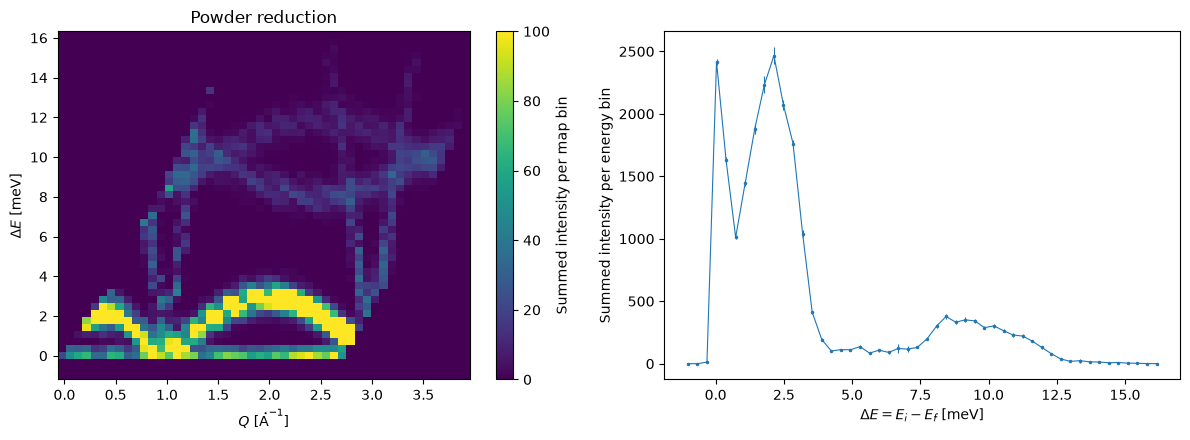

In [96]:
N_Q_BINS = 50
N_ENERGY_BINS = 50

def plot_edges(values, count):
    selected = values[signal] if signal.any() else values
    lower, upper = selected.min(), selected.max()
    margin = max(0.02*(upper-lower), 1e-6)
    return np.linspace(lower-margin, upper+margin, count+1)

q_edges = plot_edges(powder["Q_Ainv"], N_Q_BINS)
energy_edges = plot_edges(powder["energy_transfer_meV"], N_ENERGY_BINS)
map_intensity, _, _ = np.histogram2d(
    powder["Q_Ainv"], powder["energy_transfer_meV"],
    bins=(q_edges, energy_edges), weights=powder["intensity"])
map_variance, _, _ = np.histogram2d(
    powder["Q_Ainv"], powder["energy_transfer_meV"],
    bins=(q_edges, energy_edges), weights=powder["error"]**2)
map_error = np.sqrt(map_variance)
assert np.isclose(map_intensity.sum(), powder["intensity"].sum())
print("Intensity before/after binning:", powder["intensity"].sum(), map_intensity.sum())

energy_centers = (energy_edges[:-1] + energy_edges[1:])/2
spectrum = map_intensity.sum(axis=0)
spectrum_error = np.sqrt(map_variance.sum(axis=0))
if signal.any():
    print(f"Energy-spectrum maximum at {energy_centers[spectrum.argmax()]:.4f} meV")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mesh = axes[0].pcolormesh(q_edges, energy_edges, map_intensity.T, shading="auto",vmax =100)
fig.colorbar(mesh, ax=axes[0], label="Summed intensity per map bin")
axes[0].set_xlabel(r"$Q$ [$\mathrm{\mathring{A}}^{-1}$]")
axes[0].set_ylabel(r"$\Delta E$ [meV]")
axes[0].set_title("Powder reduction")
axes[1].errorbar(energy_centers, spectrum, yerr=spectrum_error,
                 fmt=".-", markersize=3, linewidth=0.8)
axes[1].set_xlabel(r"$\Delta E=E_i-E_f$ [meV]")
axes[1].set_ylabel("Summed intensity per energy bin")
fig.tight_layout()
plt.show()

In [97]:
def save_csv(path, columns):
    """Write plain ASCII CSV with units included in the column names."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savetxt(path, np.column_stack(list(columns.values())),
               delimiter=",", header=",".join(columns), comments="", fmt="%.12g")
    print(f"Saved {path}")
save_csv(OUTPUT_CSV, powder)
OUTPUT_MAP = OUTPUT_CSV.with_name(OUTPUT_CSV.stem + "_map.npz")
np.savez(OUTPUT_MAP, q_edges=q_edges, energy_edges=energy_edges,
         intensity=map_intensity, error=map_error)
print("Saved", OUTPUT_MAP)

Saved /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/full_instrument/powder_reduced.csv
Saved /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/full_instrument/powder_reduced_map.npz
